# Statistics 6: Estimation and confidence intervals

*Learning path: probability and statistics, part 6 of 8.* [Index](README.md) · Previous: [Sampling and the central limit theorem](05-sampling-and-clt.ipynb) · Next: [Hypothesis tests](07-hypothesis-tests.ipynb)

In 1798 Henry Cavendish hung two small lead balls from a wire, brought two large ones close, and measured the tiny
twist that their gravity produced. From 29 repetitions he estimated the density of the Earth, and so its mass. His
29 numbers do not agree with each other. What, then, is his answer, and how far might it be from the truth? This
lesson turns [lesson 5](05-sampling-and-clt.ipynb) around: instead of knowing the population and watching samples
vary, we have **one** sample and want to say something honest about the unknown mean. The answer is a **confidence
interval**.

**Who this is for.** You have done lessons 1 to 5, in particular the standard error $\sigma/\sqrt n$ and the value
1.96 from [lesson 4](04-continuous-distributions.ipynb).

**What you will be able to do afterwards:**

1. estimate a mean and its standard error from one sample;
2. build a 95% confidence interval and say what the 95% means;
3. use Student's t distribution when the standard deviation is estimated, with `ci` and `tinv`;
4. give a confidence interval for a proportion, and explain why the sample variance divides by $n - 1$.

Plan about an hour.

## 1. Estimates and standard errors

Cavendish's 29 measurements of the Earth's density, in grams per cubic centimetre:

In [1]:
d = [5.50 5.61 4.88 5.07 5.26 5.55 5.36 5.29 5.58 5.65 5.57 5.53 5.62 5.29 5.44 5.34 5.79 5.10 5.27 5.39 5.42 5.47 5.63 5.34 5.46 5.30 5.75 5.68 5.85];
numel(d)
mean(d)
std(d)

29

> `numel` (see `tally`): tally lists the distinct values (first row) and how often each occurs (second row); sort sorts; numel counts; cumsum gives running totals.

5.4479310344827585

> Mean: the sum of the 29 values divided by 29.

0.2209456835375872

> Sample standard deviation: the square root of the sample variance (sum of squared deviations divided by n − 1 = 28).

The sample mean $\bar x = 5.448$ is the natural **estimate** of the true density $\mu$. How precise is it? By lesson 5
the mean of $n$ values has standard deviation $\sigma/\sqrt n$. We do not know $\sigma$, but the sample standard
deviation $s = 0.221$ estimates it, which gives the **standard error** of the estimate:

In [2]:
se = eval(std(d)/sqrt(29))

0.04102858342327213

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

So Cavendish's mean is uncertain by about 0.04: the measurements scatter by 0.22, but their average of 29 is
$\sqrt{29} \approx 5.4$ times more precise.

**Try this.** If Cavendish had made 116 measurements with the same scatter, what would the standard error have been?

## 2. Confidence intervals

By the central limit theorem, $\bar x$ is approximately normal around $\mu$ with standard deviation $\sigma/\sqrt n$, so
95% of the time it lands within $1.96\,\sigma/\sqrt n$ of $\mu$. Turned around: 95% of the time, $\mu$ lies within
$1.96\,\sigma/\sqrt n$ of $\bar x$. The interval

$$\bar x \pm 1.96\,\frac{\sigma}{\sqrt n}$$

is a **95% confidence interval**. The 95% is a property of the **method**, not of one interval: one interval either
contains $\mu$ or it does not. Check it by simulation. Draw 1000 samples of 25 heights from a population with
$\mu = 170$ and $\sigma = 8$, and count how often the interval around the sample mean contains 170:

In [3]:
seed(21);
A = 170 + 8*randn(25, 1000);
m = ones(1, 25)*A/25;
sum(abs(m - 170) < 1.96*8/5)/1000

941/1000

941 of the 1000 intervals caught the true mean, close to 95%. A wider interval is more often right, and less useful.
With 1.645 in place of 1.96 we get 90% intervals:

In [4]:
sum(abs(m - 170) < 1.645*8/5)/1000

881/1000

**Try this.** What multiplier gives a 99% interval? (Use `norminv(0.995)`.) How often do the 1000 intervals then
contain 170?

## 3. Student's t: when $\sigma$ is estimated

In practice $\sigma$ is unknown and we use $s$. That adds uncertainty, especially for small samples, and the
multiplier 1.96 is then too small. William Gosset, a chemist at the Guinness brewery who published under the name
"Student", found the right distribution in 1908: $(\bar x - \mu)/(s/\sqrt n)$ follows the **t distribution** with
$n - 1$ degrees of freedom. It looks like the normal with heavier tails:

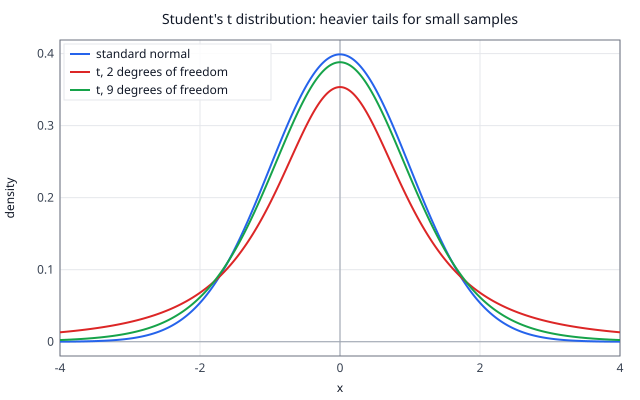

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = plot(normpdf(x), x, -4, 4);
p = show(p, plot(tpdf(x, 2), x, -4, 4));
p = show(p, plot(tpdf(x, 9), x, -4, 4));
p = legend(p, "standard normal", "t, 2 degrees of freedom", "t, 9 degrees of freedom");
labels(title(p, "Student's t distribution: heavier tails for small samples"), "x", "density")

The multipliers `tinv(0.975, n - 1)` for samples of 5, 10, 30 and 100 shrink to 1.96 as the sample grows:

In [6]:
[tinv(0.975, 4), tinv(0.975, 9), tinv(0.975, 29), tinv(0.975, 99)]

[2.7764451051978, 2.262157162798195, 2.0452296421327065, 1.9842169515864039]

> The t value with probability p below it (a critical value for confidence intervals and tests).

`ci(data)` gives the 95% interval $\bar x \pm t\,s/\sqrt n$ and explains how it got it; `ci(data, 0.99)` gives a 99%
interval. For Cavendish:

In [7]:
ci(d)
ci(d, 0.99)

[5.363887791180786, 5.531974277784731]

> 95% confidence interval for the mean: mean ± t·s/√n = 5.447931 ± 2.048407 × 0.220946/√29, with t = tinv(0.975, 28) = 2.0484 from Student's t distribution with n − 1 = 28 degrees of freedom.

[5.334558290308463, 5.561303778657054]

> 99% confidence interval for the mean: mean ± t·s/√n = 5.447931 ± 2.763262 × 0.220946/√29, with t = tinv(0.995, 28) = 2.7633 from Student's t distribution with n − 1 = 28 degrees of freedom.

The modern value of the Earth's mean density is 5.513 g/cm³, inside both intervals: Cavendish's experiment was honest
about its own precision. (Cavendish himself reported 5.48, the result of a slip in his arithmetic.)

**Try this.** Compute the 95% interval by hand: `mean(d) - tinv(0.975, 28)*se` and `mean(d) + tinv(0.975, 28)*se`.
Does it match `ci(d)`?

## 4. Intervals for proportions

A poll of 1000 voters finds 520 in favour. The estimate is $\hat p = 0.52$ with standard error
$\sqrt{\hat p(1 - \hat p)/n}$ (lesson 5), so the 95% interval is

In [8]:
phat = 520/1000;
se2 = sqrt(phat*(1 - phat)/1000);
eval([phat - 1.96*se2, phat + 1.96*se2])

[0.48903448111204983, 0.5509655188879502]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

From 48.9% to 55.1%. The interval contains values below 50%, so the poll does not settle who is ahead: "52%, margin of
error 3 points" says exactly this.

**Try this.** With the same 52%, how many voters would make the whole interval lie above 50%?

## 5. Why divide by $n - 1$?

[Lesson 1](01-describing-data.ipynb) promised a reason for the $n - 1$ in the sample variance. The deviations
$x_i - \bar x$ are measured from the sample's own mean, which sits closer to the data than the true mean does, so the
squared deviations come out too small on average. Dividing by $n - 1$ instead of $n$ corrects this exactly.

The effect is largest for samples of 2. Then $\bar x$ is halfway between $x_1$ and $x_2$, and the sum of squared
deviations is $(x_1 - x_2)^2/2$. Draw 5000 pairs from the standard normal ($\sigma^2 = 1$), and average the two
estimates:

In [9]:
seed(4);
B = randn(2, 5000);
w = [1 -1]*B;
w*w'/(2*5000)
w*w'/(4*5000)

0.9953121252241833
0.49765606261209167

Here `w` holds the differences $x_1 - x_2$, and `w*w'` adds their squares. Dividing by $n - 1 = 1$ gives an average
of 0.995, close to the true variance 1; dividing by $n = 2$ gives 0.498, half of it. An estimator whose average is
the true value is **unbiased**: with $n - 1$ the sample variance is unbiased.

**Try this.** Why does the bias of dividing by $n$ matter less for Cavendish's 29 measurements? (Compare $1/29$ and
$1/28$.)

## Summary

* The sample mean estimates $\mu$; its standard error is $s/\sqrt n$.
* A 95% confidence interval comes from a method that catches the true value in 95% of samples:
  $\bar x \pm 1.96\,\sigma/\sqrt n$ when $\sigma$ is known.
* With $\sigma$ estimated by $s$, use Student's t with $n - 1$ degrees of freedom: $\bar x \pm t\,s/\sqrt n$, with
  `ci(data)` and `tinv`.
* For a proportion, $\hat p \pm 1.96\sqrt{\hat p(1 - \hat p)/n}$.
* The sample variance divides by $n - 1$ to be unbiased.

Next: [hypothesis tests](07-hypothesis-tests.ipynb), which ask whether data are surprising under a given claim.

## Exercises

1. **Small sample.** Five measurements of a resistor give 5.1, 4.9, 5.6, 5.3 and 5.0 ohms. Give a 95% interval for
   the true resistance.
2. **Planning a study.** How many measurements with standard deviation 0.22 are needed for a 95% interval of half
   width 0.02?
3. **The meaning of 95%.** A student says: "there is a 95% probability that the true density is between 5.36 and
   5.53". Explain what is wrong, and give a correct statement.
4. **Coverage with t.** In the simulation of section 2, the intervals used the true $\sigma = 8$. Explain why using
   1.96 with $s$ instead would cover less than 95% for samples of 5.
5. **Dropping a value.** Cavendish's sixth value, 4.88, came from a different wire. Remove it and recompute `ci`. Does
   the interval still contain 5.513?

## Hints and answers

* **Section 1, Try this.** Four times the data halves the error: about 0.021.
* **Section 2, Try this.** `norminv(0.995)` $\approx 2.576$; 986 of the 1000 intervals contain 170.
* **Section 3, Try this.** Yes: both give $[5.364, 5.532]$.
* **Section 4, Try this.** The half width $1.96\sqrt{0.52 \cdot 0.48/n}$ must be below 0.02: about 2400 voters.
* **Section 5, Try this.** $1/29$ and $1/28$ differ by about 3.5%, a small fraction of the standard error.
* **Exercise 1.** `ci([5.1 4.9 5.6 5.3 5.0])` gives about $[4.84, 5.52]$; the t multiplier is 2.78.
* **Exercise 2.** $n = (1.96 \cdot 0.22/0.02)^2 \approx 465$.
* **Exercise 3.** The true density is fixed, not random. Correct: the interval comes from a method that catches the
  true value in 95% of samples.
* **Exercise 4.** $s$ varies from sample to sample and is often too small; the heavier tails of t, with multiplier
  2.78 for 4 degrees of freedom, compensate.
* **Exercise 5.** The mean rises to 5.468 and the interval becomes about $[5.39, 5.54]$, which still contains 5.513.

## Sources

1. H. Cavendish, "Experiments to determine the density of the Earth", *Philosophical Transactions of the Royal
   Society* 88 (1798) 469–526.
2. Student (W. S. Gosset), "The probable error of a mean", *Biometrika* 6 (1908) 1–25.
3. J. Neyman, "Outline of a theory of statistical estimation based on the classical theory of probability",
   *Philosophical Transactions of the Royal Society A* 236 (1937) 333–380 (confidence intervals).
4. S. M. Stigler, "Do robust estimators deal with real data?", *Annals of Statistics* 5 (1977) 1055–1078 (Cavendish's
   data).